# 06 · Comparación de resultados de los cinco experimentos

Reúne lo que dejaron los notebooks 01–05 en `resultados/` y responde las preguntas del trabajo:

1. **¿Qué enfoque recomienda mejor el cine mexicano?** Filtrado colaborativo (exp. 1–2) vs. basado en contenido (exp. 3).
2. **¿Influye el perfil del usuario?** Espectador ocasional, 3–4 películas mexicanas (exp. 1) vs. asiduo, ≥ 5 (exp. 2).
3. **¿Mejora la recomendación al incorporar el sentimiento de las reseñas?** Variante A (estrellas) vs. B (BETO) vs. C (JEV).
4. **¿Qué analizador de sentimiento es mejor?** BETO (exp. 4) vs. JEV (exp. 5).

Se puede correr en cualquier momento: usa lo que exista y señala lo que falta. Genera `resultados/comparacion/resumen_resultados.md`.

In [1]:
# --- Configuración del entorno ---------------------------------------------
# En la Mac no hay que cambiar nada. En Colab u otro servidor: sube la carpeta
# TT_Recomendador_Cine_Mexicano (basta con src/ y datos/limpios/) y descomenta:
# from google.colab import drive
# drive.mount('/content/drive')
# import os; os.environ['TT_RAIZ'] = '/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano'

import os, sys, warnings
from pathlib import Path
RAIZ = Path(os.environ.get('TT_RAIZ', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
os.environ['TT_RAIZ'] = str(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
warnings.filterwarnings('ignore', category=FutureWarning)
print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: /Users/irving/Documents/TrabajoTerminal/TT_Recomendador_Cine_Mexicano


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recomendador import rutas

SALIDA = rutas.carpeta_resultados('comparacion')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
NOMBRE_VARIANTE = {'A': 'A · estrellas', 'B': 'B · +BETO', 'C': 'C · +JEV'}
NOMBRE_GRUPO = {'g34': '3–4 películas MX', 'g5': '≥5 películas MX'}

def leer(ruta, **kw):
    ruta = rutas.RESULTADOS / ruta
    return pd.read_csv(ruta, **kw) if ruta.exists() else None

faltan = []
partes = []
for exp, grupo in (('exp1', 'g34'), ('exp2', 'g5')):
    r = leer(f'{exp}/ranking_test.csv')
    if r is None: faltan.append(exp); continue
    partes.append(r.assign(experimento=exp, grupo=grupo, enfoque='Colaborativo'))
r3 = leer('exp3/ranking_test.csv')
if r3 is None: faltan.append('exp3')
else: partes.append(r3.assign(experimento='exp3', enfoque='Contenido'))
ranking = pd.concat(partes, ignore_index=True)
# Popularidad aparece en los tres experimentos con los mismos usuarios: se deja una vez, como referencia
ranking.loc[ranking.modelo == 'Popularidad', 'enfoque'] = 'Referencia'
ranking = ranking.drop_duplicates(['grupo', 'modelo', 'variante'])
ranking['grupo_nombre'] = ranking.grupo.map(NOMBRE_GRUPO)
print('Faltan resultados de:', faltan or 'ninguno')
print('Variantes presentes:', sorted(ranking.variante.unique()))

Faltan resultados de: ninguno
Variantes presentes: ['A']


## 1. Cuadro principal (prueba, @10)

In [3]:
METRICAS = ['Precision@10', 'Recall@10', 'nDCG@10', 'HitRate@10', 'MRR@10']
principal = (ranking[ranking.variante == 'A']
             .set_index(['grupo_nombre', 'enfoque', 'modelo'])[METRICAS + ['Cobertura@10', 'Novedad@10']]
             .sort_index())
principal.to_csv(SALIDA / 'cuadro_principal_variante_A.csv')
principal

Precision@10  \
grupo_nombre     enfoque      modelo                                            
3–4 películas MX Colaborativo EASE                                     0.0259   
                              ItemKNN                                  0.0128   
                              PureSVD                                  0.0204   
                 Contenido    Contenido-Embeddings                     0.0111   
                              Contenido-Embeddings (solo texto)        0.0032   
                              Contenido-TFIDF                          0.0105   
                              Contenido-TFIDF (solo texto)             0.0027   
                 Referencia   Popularidad                              0.0064   
≥5 películas MX  Colaborativo EASE                                     0.0440   
                              ItemKNN                                  0.0228   
                              PureSVD                                  0.0351   
                 Contenido    Contenido-Embeddings                     0.0179   
                              Contenido-Embeddings (solo texto)        0.0047   
                              Contenido-TFIDF                          0.0183   
                              Contenido-TFIDF (solo texto)             0.0054   
                 Referencia   Popularidad                              0.0073   

                                                                 Recall@10  \
grupo_nombre     enfoque      modelo                                         
3–4 películas MX Colaborativo EASE                                  0.2591   
                              ItemKNN                               0.1281   
                              PureSVD                               0.2043   
                 Contenido    Contenido-Embeddings                  0.1109   
                              Contenido-Embeddings (solo texto)     0.0321   
                              Contenido-TFIDF                       0.1046   
                              Contenido-TFIDF (solo texto)          0.0271   
                 Referencia   Popularidad                           0.0638   
≥5 películas MX  Colaborativo EASE                                  0.2897   
                              ItemKNN                               0.1490   
                              PureSVD                               0.2311   
                 Contenido    Contenido-Embeddings                  0.1178   
                              Contenido-Embeddings (solo texto)     0.0319   
                              Contenido-TFIDF                       0.1199   
                              Contenido-TFIDF (solo texto)          0.0351   
                 Referencia   Popularidad                           0.0512   

                                                                 nDCG@10  \
grupo_nombre     enfoque      modelo                                       
3–4 películas MX Colaborativo EASE                                0.1374   
                              ItemKNN                             0.0576   
                              PureSVD                             0.1132   
                 Contenido    Contenido-Embeddings                0.0641   
                              Contenido-Embeddings (solo texto)   0.0176   
                              Contenido-TFIDF                     0.0623   
                              Contenido-TFIDF (solo texto)        0.0146   
                 Referencia   Popularidad                         0.0269   
≥5 películas MX  Colaborativo EASE                                0.1737   
                              ItemKNN                             0.0793   
                              PureSVD                             0.1431   
                 Contenido    Contenido-Embeddings                0.0740   
                              Contenido-Embeddings (solo texto)   0.0182   
                              Contenido-TFIDF                

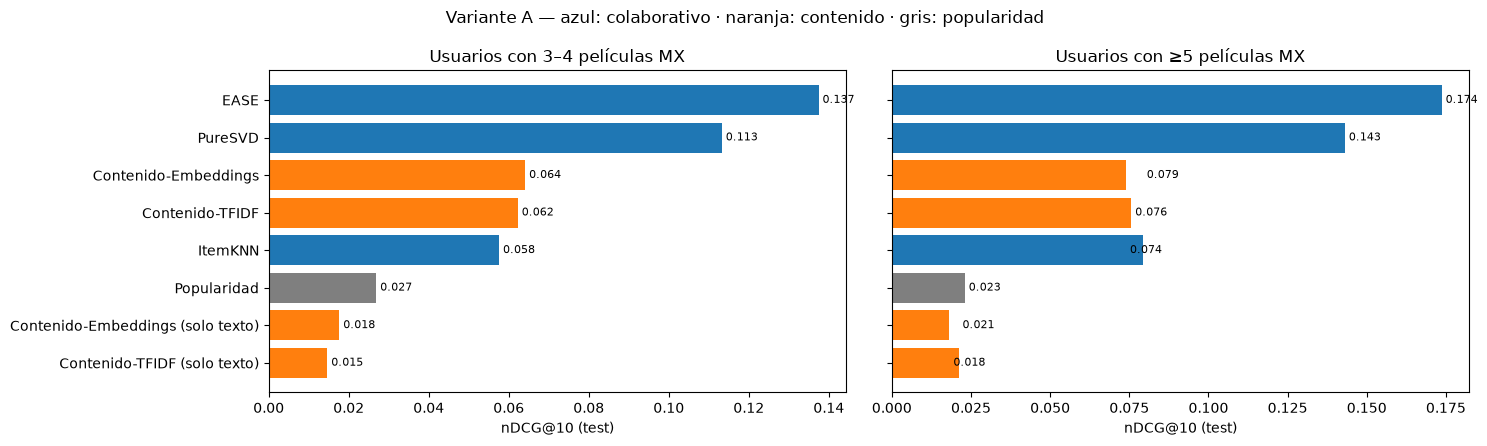

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for eje, (grupo, d) in zip(ejes, ranking[ranking.variante == 'A'].groupby('grupo')):
    d = d.drop_duplicates('modelo').set_index('modelo').sort_values('nDCG@10')
    colores = [{'Referencia': 'tab:gray', 'Colaborativo': 'tab:blue'}.get(e, 'tab:orange') for e in d.enfoque]
    eje.barh(d.index, d['nDCG@10'], color=colores)
    for y, v in enumerate(d['nDCG@10']): eje.text(v, y, f' {v:.3f}', va='center', fontsize=8)
    eje.set(title=f'Usuarios con {NOMBRE_GRUPO[grupo]}', xlabel='nDCG@10 (test)')
fig.suptitle('Variante A — azul: colaborativo · naranja: contenido · gris: popularidad')
fig.tight_layout(); fig.savefig(SALIDA / 'ndcg10_por_modelo.png', dpi=130)

## 2. Ocasional vs. asiduo (experimento 1 vs. 2)

In [5]:
cf_a = ranking[(ranking.enfoque == 'Colaborativo') & (ranking.variante == 'A')]
grupos = cf_a.pivot_table(index='modelo', columns='grupo_nombre', values=['nDCG@10', 'Recall@10', 'HitRate@10'])
grupos

HitRate@10                        Recall@10  \
grupo_nombre 3–4 películas MX ≥5 películas MX 3–4 películas MX   
modelo                                                           
EASE                   0.2591          0.3733           0.2591   
ItemKNN                0.1281          0.2044           0.1281   
PureSVD                0.2043          0.3067           0.2043   

                                      nDCG@10                  
grupo_nombre ≥5 películas MX 3–4 películas MX ≥5 películas MX  
modelo                                                         
EASE                  0.2897           0.1374          0.1737  
ItemKNN               0.1490           0.0576          0.0793  
PureSVD               0.2311           0.1132          0.1431

## 3. Efecto del sentimiento (variantes B y C)

In [6]:
if ranking.variante.nunique() > 1:
    efecto = ranking[ranking.modelo != 'Popularidad'].pivot_table(
        index=['grupo_nombre', 'enfoque', 'modelo'], columns='variante', values='nDCG@10')
    for v in [c for c in efecto.columns if c != 'A']:
        efecto[f'{v} vs A (%)'] = 100 * (efecto[v] / efecto['A'] - 1)
    display(efecto)
    partes_sig = []
    for e in ('exp1', 'exp2', 'exp3'):
        d = leer(f'{e}/significancia.csv')
        if d is not None and len(d):
            partes_sig.append(d.assign(experimento=e))
    sig = pd.concat(partes_sig, ignore_index=True) if partes_sig else pd.DataFrame()
    if len(sig):
        if 'grupo' not in sig:
            sig['grupo'] = np.nan
        sig['grupo'] = sig['grupo'].fillna(sig.experimento.map({'exp1': 'g34', 'exp2': 'g5'}))
        sig.to_csv(SALIDA / 'significancia_todas.csv', index=False)
        display(sig[['experimento', 'grupo', 'modelo', 'variante', 'metrica', 'usuarios', 'media_A', 'media_variante',
                     'mejora_relativa', 'usuarios_mejoran', 'usuarios_empeoran', 'p_valor', 'significativo_5%']])
else:
    efecto, sig = None, pd.DataFrame()
    print('Todavía solo existe la variante A. Ejecuta 04 (BETO) y/o 05 (JEV) y después 01–03.')

Todavía solo existe la variante A. Ejecuta 04 (BETO) y/o 05 (JEV) y después 01–03.


## 4. BETO vs. JEV como analizadores de sentimiento

In [7]:
analizadores = {}
for exp, nombre in (('exp4', 'beto'), ('exp5', 'jev')):
    ruta = rutas.RESULTADOS / exp / f'metricas_sentimiento_{nombre}.json'
    if ruta.exists():
        analizadores[nombre.upper()] = json.loads(ruta.read_text())
if analizadores:
    claves = ['modelo', 'resenas_evaluadas', 'exactitud', 'f1_macro', 'kappa_cohen', 'f1_negativo', 'f1_neutral',
              'f1_positivo', 'spearman_s_vs_estrellas', 'mae_estrellas']
    tabla_sent = pd.DataFrame(analizadores).reindex(claves)
    tabla_sent.to_csv(SALIDA / 'analizadores_sentimiento.csv')
    display(tabla_sent)
    acuerdo = rutas.RESULTADOS / 'exp5' / 'acuerdo_beto_jev.json'
    if acuerdo.exists():
        display(pd.Series(json.loads(acuerdo.read_text())).to_frame('BETO vs JEV'))
else:
    tabla_sent = None
    print('Aún no hay métricas de BETO ni de JEV (notebooks 04 y 05).')

Aún no hay métricas de BETO ni de JEV (notebooks 04 y 05).


## 5. Resumen en Markdown

In [8]:
def tabla_md(df, decimales=4):
    df = df.reset_index()
    fmt = lambda v: f'{v:.{decimales}f}' if isinstance(v, (float, np.floating)) else str(v)
    filas = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)]
    filas += ['| ' + ' | '.join(fmt(v) for v in fila) + ' |' for fila in df.itertuples(index=False)]
    return '\n'.join(filas)

lineas = ['# Resumen de resultados', '',
          'Generado por `notebooks/06_comparacion_resultados.ipynb`. Métricas en el conjunto de prueba, '
          'relevante = película mexicana retenida calificada con ≥ 3.5 ★, ranking sobre las 878 películas del catálogo.', '',
          '## Variante A (solo estrellas)', '', tabla_md(principal), '']
for grupo, d in ranking[ranking.variante == 'A'].groupby('grupo'):
    mejor = d.loc[d['nDCG@10'].idxmax()]
    pop = d[d.modelo == 'Popularidad'].iloc[0]
    lineas.append(f"- **{NOMBRE_GRUPO[grupo]}**: mejor modelo **{mejor.modelo}** ({mejor.enfoque.lower()}), "
                  f"nDCG@10 = {mejor['nDCG@10']:.4f}, Recall@10 = {mejor['Recall@10']:.4f}, "
                  f"HitRate@10 = {mejor['HitRate@10']:.4f} (×{mejor['nDCG@10']/pop['nDCG@10']:.1f} sobre popularidad).")
lineas.append('')
if efecto is not None:
    lineas += ['## Efecto del sentimiento (nDCG@10)', '', tabla_md(efecto), '']
    if len(sig):
        lineas += ['### Prueba de Wilcoxon contra la variante A', '',
                   tabla_md(sig[['experimento', 'grupo', 'modelo', 'variante', 'metrica', 'mejora_relativa', 'p_valor', 'significativo_5%']]), '']
else:
    lineas += ['## Efecto del sentimiento', '', '_Pendiente: ejecutar los notebooks 04 y 05 y después 01–03._', '']
if tabla_sent is not None:
    lineas += ['## Analizadores de sentimiento', '', tabla_md(tabla_sent), '']
else:
    lineas += ['## Analizadores de sentimiento', '', '_Pendiente: ejecutar los notebooks 04 (BETO) y 05 (JEV)._', '']

(SALIDA / 'resumen_resultados.md').write_text('\n'.join(lineas), encoding='utf-8')
print('\n'.join(lineas))

# Resumen de resultados

Generado por `notebooks/06_comparacion_resultados.ipynb`. Métricas en el conjunto de prueba, relevante = película mexicana retenida calificada con ≥ 3.5 ★, ranking sobre las 878 películas del catálogo.

## Variante A (solo estrellas)

| grupo_nombre | enfoque | modelo | Precision@10 | Recall@10 | nDCG@10 | HitRate@10 | MRR@10 | Cobertura@10 | Novedad@10 |
|---|---|---|---|---|---|---|---|---|---|
| 3–4 películas MX | Colaborativo | EASE | 0.0259 | 0.2591 | 0.1374 | 0.2591 | 0.1004 | 0.3770 | 5.3326 |
| 3–4 películas MX | Colaborativo | ItemKNN | 0.0128 | 0.1281 | 0.0576 | 0.1281 | 0.0366 | 0.3360 | 4.7006 |
| 3–4 películas MX | Colaborativo | PureSVD | 0.0204 | 0.2043 | 0.1132 | 0.2043 | 0.0857 | 0.2677 | 5.7152 |
| 3–4 películas MX | Contenido | Contenido-Embeddings | 0.0111 | 0.1109 | 0.0641 | 0.1109 | 0.0497 | 0.9954 | 9.0088 |
| 3–4 películas MX | Contenido | Contenido-Embeddings (solo texto) | 0.0032 | 0.0321 | 0.0176 | 0.0321 | 0.0133 | 1.0000 | 9.6411 |
